# TP3 : Moteur de recherche d'images par le contenu - Approche Deep

**Réalisé par :** Melki Meriem
**Classe :** RT5 - Groupe 2

Dans les TP précédents, les descripteurs (couleur, texture, forme) étaient définis à la main. Ici on utilise l'apprentissage profond pour obtenir les descripteurs automatiquement. On compare deux approches :

1. **CNN pré-entraîné (VGG16)** : un réseau déjà entraîné sur ImageNet (1,2 million d'images, 1000 classes). On retire la partie classification et on garde la partie convolutionnelle comme extracteur de caractéristiques.
2. **Autoencodeur** : un réseau qu'on entraîne nous-mêmes à compresser une image dans un petit vecteur (code latent) puis à la reconstruire. Le code latent sert de descripteur.

Le principe du CBIR ne change pas : on calcule un descripteur pour chaque image de la base (indexation), puis on compare le descripteur de l'image requête avec ceux de la base (recherche).

Base utilisée : extrait de la base Corel, 10 classes, déjà divisée en train et test. Les images de train forment la base de recherche, les images de test servent de requêtes.

## 2. Importer les librairies nécessaires

In [22]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


## 3. Chargement et prétraitement des images

In [23]:
EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp')

for racine, dossiers, fichiers in os.walk('/kaggle/input'):
    nb_img = len([f for f in fichiers if f.lower().endswith(EXTENSIONS)])
    niveau = racine.replace('/kaggle/input', '').count(os.sep)
    if niveau <= 4:
        print('    ' * niveau + os.path.basename(racine) + '/', f'({nb_img} images)' if nb_img else '')

input/ 
    datasets/ 
        meriemmelki/ 
            deepcbir-dataset/ 
                DeepCBIR_Dataset/ 


Les images n'ont pas toutes la même taille. Les réseaux de neurones demandent une taille d'entrée fixe, on redimensionne donc toutes les images en 224x224 (taille d'entrée de VGG16).

In [24]:
TAILLE = 224

def chercher_dossier(nom):
    for d in sorted(glob.glob('/kaggle/input/**/', recursive=True)):
        if os.path.basename(os.path.normpath(d)).lower() == nom:
            return d
    raise FileNotFoundError("Dossier introuvable : " + nom)

def charger_images(dossier):
    images, labels = [], []
    for classe in sorted(os.listdir(dossier)):
        chemin_classe = os.path.join(dossier, classe)
        if not os.path.isdir(chemin_classe):
            continue
        for f in sorted(os.listdir(chemin_classe)):
            if f.lower().endswith(EXTENSIONS):
                img = cv2.imread(os.path.join(chemin_classe, f))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (TAILLE, TAILLE))
                images.append(img)
                labels.append(classe)
    return np.array(images), np.array(labels)

dossier_train = chercher_dossier('training_set')
dossier_test = chercher_dossier('test_set')

X_train, y_train = charger_images(dossier_train)
X_test, y_test = charger_images(dossier_test)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)
print("Classes :", np.unique(y_train))

Train : (900, 224, 224, 3)
Test  : (100, 224, 224, 3)
Classes : ['beaches' 'bus' 'dinosaurs' 'elephants' 'flowers' 'foods' 'horses'
 'monuments' 'mountains_and_snow' 'peolpe_and_villages_in_Africa']


Affichage de quelques images aléatoires de la base d'entraînement :

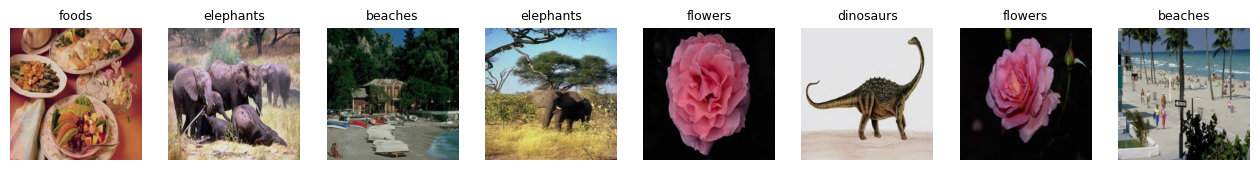

In [25]:
idx = random.sample(range(len(X_train)), 8)
plt.figure(figsize=(16, 4))
for i, k in enumerate(idx):
    plt.subplot(1, 8, i + 1)
    plt.imshow(X_train[k])
    plt.title(y_train[k], fontsize=9)
    plt.axis('off')
plt.show()

## 4. CNN pré-entraîné sur la base ImageNet

### Construction du Feature Extractor

VGG16 est composé de 13 couches de convolution réparties en 5 blocs, suivies de 3 couches denses pour la classification des 1000 classes d'ImageNet.

- `weights='imagenet'` : on charge les poids appris sur ImageNet.
- `include_top=False` : on retire les couches denses de classification, elles sont spécifiques aux 1000 classes d'ImageNet. On garde seulement les couches de convolution qui extraient des caractéristiques générales.
- `pooling='avg'` : la sortie du dernier bloc est de taille 7x7x512. Le Global Average Pooling fait la moyenne de chaque carte, on obtient un vecteur de 512 valeurs par image.
- `trainable=False` : on ne modifie pas les poids, le réseau sert seulement à extraire les descripteurs.

In [26]:
vgg = VGG16(weights='imagenet', include_top=False, pooling='avg', input_shape=(TAILLE, TAILLE, 3))
vgg.trainable = False
vgg.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

### Extraction des descripteurs CNN

Avant de passer les images au réseau, on applique `preprocess_input` : c'est le même prétraitement que celui utilisé pendant l'entraînement de VGG16 sur ImageNet (passage en BGR et soustraction de la moyenne de chaque canal).

In [27]:
cnn_train = vgg.predict(preprocess_input(X_train.astype('float32')), batch_size=16)
cnn_test = vgg.predict(preprocess_input(X_test.astype('float32')), batch_size=16)

print("Descripteurs CNN train :", cnn_train.shape)
print("Descripteurs CNN test  :", cnn_test.shape)

57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step
Descripteurs CNN train : (900, 512)
Descripteurs CNN test  : (100, 512)


### Visualisation des Feature Maps

Une feature map est la sortie d'un filtre de convolution : elle montre les zones de l'image où le filtre réagit fortement. On compare les cartes de trois couches : le début (block1), le milieu (block3) et la fin du réseau (block5).

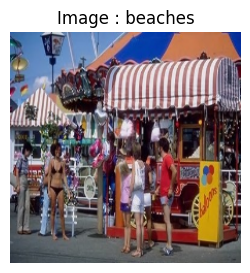

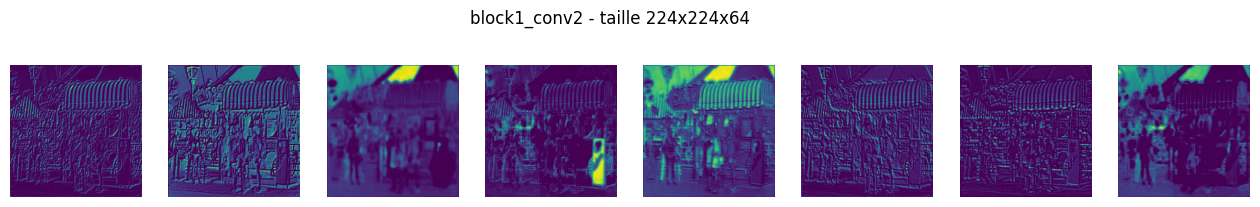

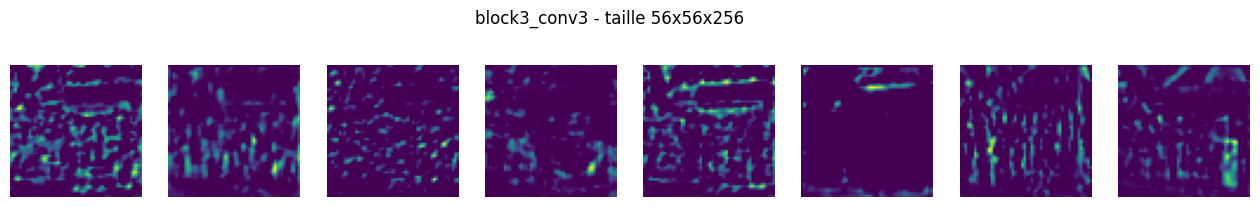

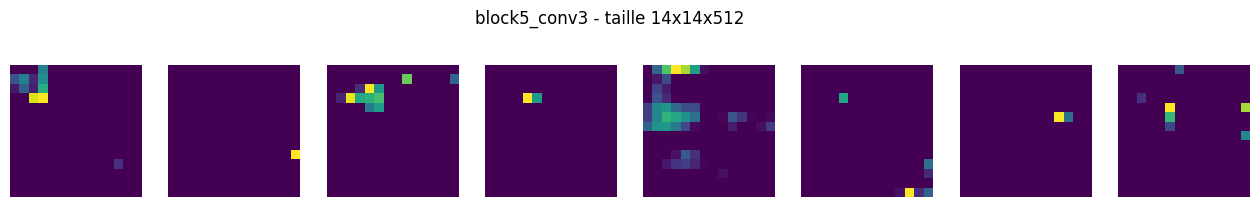

In [28]:
couches = ['block1_conv2', 'block3_conv3', 'block5_conv3']
modele_fm = Model(inputs=vgg.input, outputs=[vgg.get_layer(n).output for n in couches])

img = X_test[0]
cartes = modele_fm.predict(preprocess_input(img[None].astype('float32')), verbose=0)

plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.title("Image : " + y_test[0])
plt.axis('off')
plt.show()

for nom, fm in zip(couches, cartes):
    plt.figure(figsize=(16, 2.5))
    for i in range(8):
        plt.subplot(1, 8, i + 1)
        plt.imshow(fm[0, :, :, i], cmap='viridis')
        plt.axis('off')
    plt.suptitle(f"{nom} - taille {fm.shape[1]}x{fm.shape[2]}x{fm.shape[3]}")
    plt.show()

**Interprétation :**
- **block1_conv2 (224x224)** : les cartes ressemblent encore à l'image. Certains filtres détectent les contours (rayures du store, silhouettes des personnes), d'autres réagissent à une couleur précise (le panneau jaune, le ciel).
- **block3_conv3 (56x56)** : l'image n'est plus reconnaissable. Les filtres réagissent à des textures et à des petits motifs répartis dans l'image.
- **block5_conv3 (14x14)** : seuls quelques pixels sont activés. Chaque filtre réagit à la présence d'une partie d'objet précise, ici surtout en haut de l'image (zone du store et du ciel).

Le réseau passe donc d'informations simples (contours, couleurs) à des informations plus abstraites et sémantiques. C'est la sortie de ce dernier bloc qu'on utilise comme descripteur.

## 5. Autoencodeur profond

Un autoencodeur est composé de deux parties :
- **l'encodeur** compresse l'image en un vecteur de petite taille (le code latent),
- **le décodeur** reconstruit l'image à partir de ce code.

Il est entraîné à reproduire en sortie l'image d'entrée, en minimisant l'erreur de reconstruction (MSE). Pour bien reconstruire, le code latent doit garder l'information la plus importante de l'image : on peut donc l'utiliser comme descripteur. L'entraînement n'a pas besoin des étiquettes (apprentissage non supervisé).

Pour réduire le temps de calcul, on travaille en 128x128 et on normalise les pixels entre 0 et 1.

In [29]:
TAILLE_AE = 128
code_size = 256

Xa_train = np.array([cv2.resize(im, (TAILLE_AE, TAILLE_AE)) for im in X_train]).astype('float32') / 255
Xa_test = np.array([cv2.resize(im, (TAILLE_AE, TAILLE_AE)) for im in X_test]).astype('float32') / 255
print(Xa_train.shape, Xa_test.shape)

(900, 128, 128, 3) (100, 128, 128, 3)


### Build Autoencoder
- **Encodeur** : 3 blocs Conv2D + MaxPooling2D (128 -> 64 -> 32 -> 16), puis Flatten et Dense(code_size).
- **Décodeur** : Dense + Reshape pour revenir à 16x16x128, puis 3 Conv2DTranspose (16 -> 32 -> 64 -> 128) et une dernière Conv2D avec 3 filtres et une activation sigmoïde pour avoir des pixels entre 0 et 1.

In [30]:
# Encodeur
entree = layers.Input(shape=(TAILLE_AE, TAILLE_AE, 3))
x = layers.Conv2D(32, 3, activation='relu', padding='same')(entree)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Flatten()(x)
code_latent = layers.Dense(code_size, name='code')(x)
encoder = Model(entree, code_latent, name='encoder')

# Decodeur
entree_code = layers.Input(shape=(code_size,))
y = layers.Dense(16 * 16 * 128, activation='relu')(entree_code)
y = layers.Reshape((16, 16, 128))(y)
y = layers.Conv2DTranspose(128, 3, strides=2, activation='relu', padding='same')(y)
y = layers.Conv2DTranspose(64, 3, strides=2, activation='relu', padding='same')(y)
y = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(y)
sortie = layers.Conv2D(3, 3, activation='sigmoid', padding='same')(y)
decoder = Model(entree_code, sortie, name='decoder')

# Autoencodeur complet : image -> code -> image reconstruite
autoencoder = Model(entree, decoder(encoder(entree)), name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Dense)                    │ (None, 256)            │     8,388,864 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,482,112 (32.36 MB)

 Trainable params: 8,482,112 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32768)          │     8,421,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,662,083 (33.04 MB)

 Trainable params: 8,662,083 (33.04 MB)

 Non-trainable params: 0 (0.00 B)

### Entraînement
L'entrée et la sortie attendue sont les mêmes images. Les images de test servent de validation pour vérifier que le modèle ne fait pas que mémoriser les images d'entraînement.

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - loss: 0.0754 - val_loss: 0.0611
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0450 - val_loss: 0.0430
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0368 - val_loss: 0.0383
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0332 - val_loss: 0.0344
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0295 - val_loss: 0.0308
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0270 - val_loss: 0.0293
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0251 - val_loss: 0.0285
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0235 - val_loss: 0.0270
Epoch 9/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0218 - val_loss: 0.0269
Epoch 10/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0209 - val_loss: 0.0266
Epoch 11/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0196 - val_loss: 0.0265
Epoch 12/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0

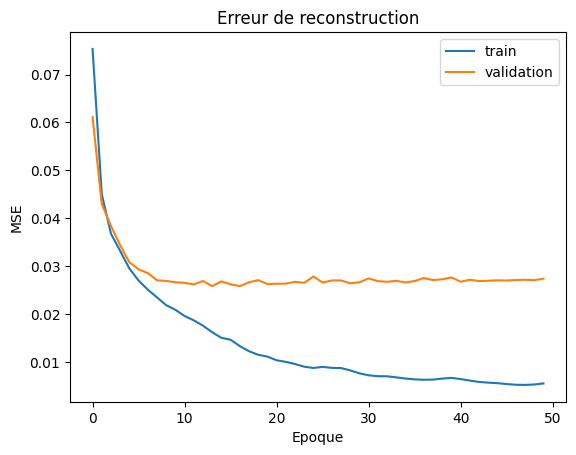

In [31]:
historique = autoencoder.fit(Xa_train, Xa_train,
                             validation_data=(Xa_test, Xa_test),
                             epochs=50, batch_size=16, verbose=1)

plt.plot(historique.history['loss'], label='train')
plt.plot(historique.history['val_loss'], label='validation')
plt.xlabel('Epoque')
plt.ylabel('MSE')
plt.title("Erreur de reconstruction")
plt.legend()
plt.show()

**Interprétation :**
L'erreur d'entraînement baisse de 0.079 à 0.005 sur les 50 époques. L'erreur de validation baisse jusqu'à environ 0.026 vers l'époque 12, puis elle ne diminue plus. Après cette époque, le modèle apprend par coeur les images d'entraînement au lieu de mieux généraliser : c'est du surapprentissage. C'est normal car l'encodeur a environ 8,5 millions de paramètres pour seulement 900 images. On aurait pu arrêter l'entraînement vers l'époque 12.

### Extraction des descripteurs
Une fois l'autoencodeur entraîné, on n'utilise plus que l'encodeur : chaque image donne un vecteur de 256 valeurs.

In [32]:
descriptors_train = encoder.predict(Xa_train)
descriptors_test = encoder.predict(Xa_test)

print("Descripteurs AE train :", descriptors_train.shape)
print("Descripteurs AE test  :", descriptors_test.shape)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Descripteurs AE train : (900, 256)
Descripteurs AE test  : (100, 256)


### Visualisation du vecteur latent de l'autoencodeur
On affiche pour une image : l'image originale, son code latent (256 valeurs) et l'image reconstruite par le décodeur à partir de ce code.

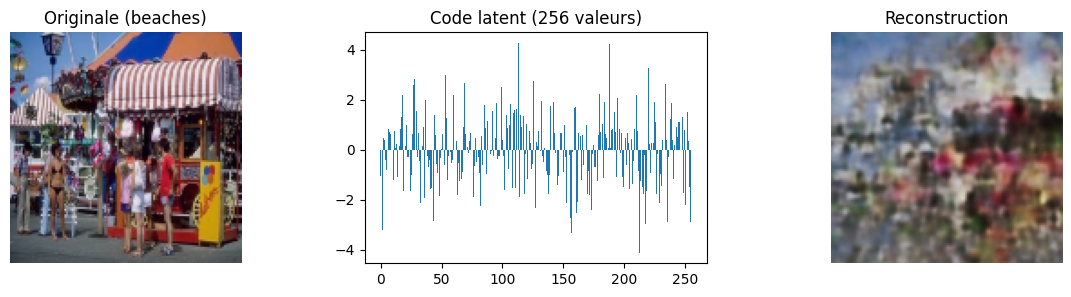

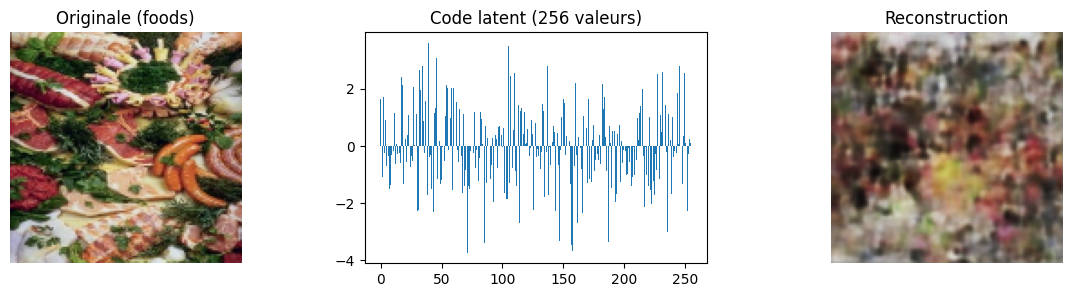

In [33]:
for k in [0, len(Xa_test) // 2]:
    img = Xa_test[k]
    code = encoder.predict(img[None], verbose=0)[0]
    reconstruction = decoder.predict(code[None], verbose=0)[0]

    plt.figure(figsize=(15, 3))
    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Originale (" + y_test[k] + ")")
    plt.axis('off')
    plt.subplot(1, 3, 2)
    plt.bar(range(code_size), code)
    plt.title("Code latent (256 valeurs)")
    plt.subplot(1, 3, 3)
    plt.imshow(reconstruction)
    plt.title("Reconstruction")
    plt.axis('off')
    plt.show()

**Interprétation :**
Les reconstructions sont très floues. Pour l'image de plage, on retrouve des taches de couleur (le ciel bleu en haut, du rouge en bas) mais ni les personnes ni le store ne sont reconnaissables. Pour l'image de nourriture, on retrouve seulement le mélange de rouge, vert et blanc. Le code latent garde donc surtout les couleurs et leur répartition générale, pas les objets. Les valeurs du code latent elles-mêmes ne sont pas interprétables à l'oeil : les deux codes se ressemblent alors que les images sont très différentes.

## 6. Recherche d'images similaires

Les images de test sont les requêtes et les images de train forment la base. Pour comparer deux descripteurs on peut utiliser :
- **la distance euclidienne** : $d(a,b) = \sqrt{\sum_i (a_i - b_i)^2}$, plus elle est petite plus les images sont proches,
- **la similarité cosinus** : $\cos(a,b) = \frac{a \cdot b}{\|a\| \|b\|}$, elle mesure l'angle entre les deux vecteurs et ne dépend pas de leur norme. Plus elle est proche de 1, plus les images sont proches.

In [34]:
def rechercher(desc_req, desc_base, k=5, mesure='cosinus'):
    if mesure == 'cosinus':
        a = desc_req / (np.linalg.norm(desc_req) + 1e-10)
        B = desc_base / (np.linalg.norm(desc_base, axis=1, keepdims=True) + 1e-10)
        sim = B @ a
        ordre = np.argsort(-sim)          # du plus similaire au moins similaire
        return ordre[:k], sim[ordre[:k]]
    else:
        d = np.sqrt(np.sum((desc_base - desc_req) ** 2, axis=1))
        ordre = np.argsort(d)
        return ordre[:k], d[ordre[:k]]

def afficher_resultats(i_req, desc_test, desc_train, titre, mesure='cosinus', k=5):
    ordre, scores = rechercher(desc_test[i_req], desc_train, k, mesure)
    plt.figure(figsize=(3 * (k + 1), 3))
    plt.subplot(1, k + 1, 1)
    plt.imshow(X_test[i_req])
    plt.title("Requete : " + y_test[i_req], fontsize=9)
    plt.axis('off')
    for j, (idx, s) in enumerate(zip(ordre, scores)):
        plt.subplot(1, k + 1, j + 2)
        plt.imshow(X_train[idx])
        couleur = 'green' if y_train[idx] == y_test[i_req] else 'red'
        plt.title(f"{y_train[idx]}\n{s:.3f}", fontsize=9, color=couleur)
        plt.axis('off')
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()

Résultats pour trois images requêtes (titre en vert : même classe que la requête, en rouge : classe différente).

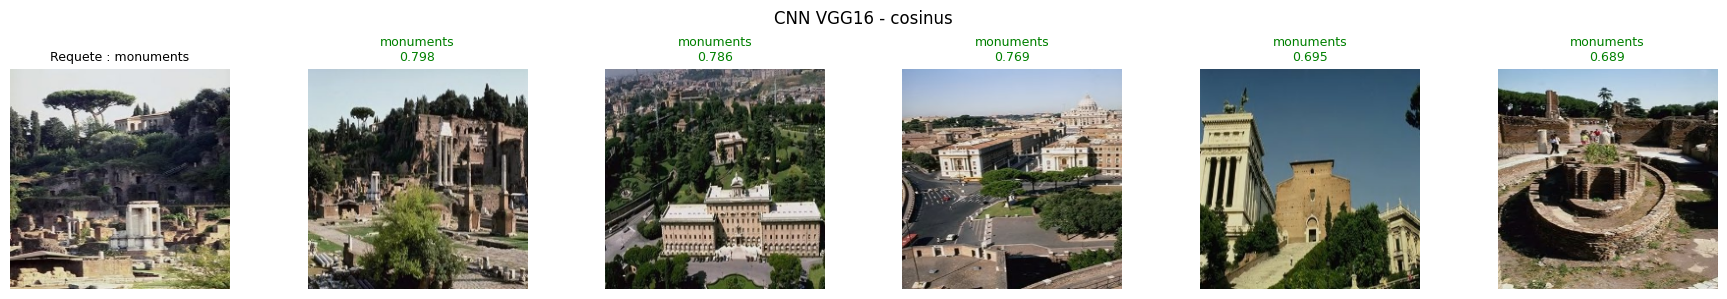

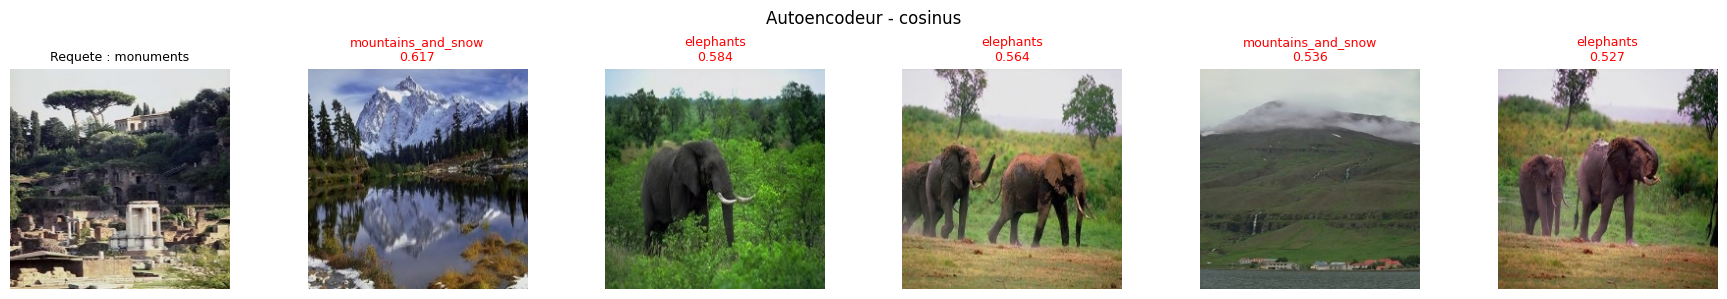

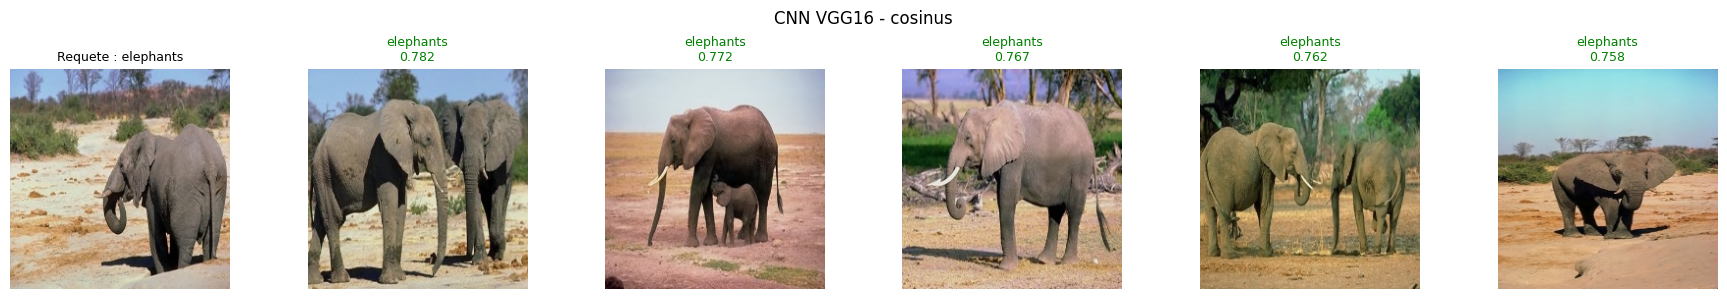

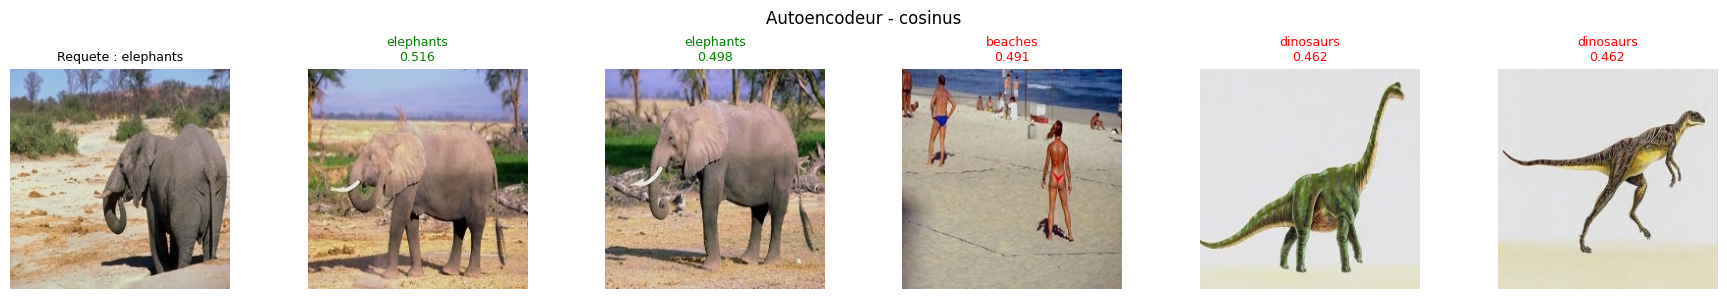

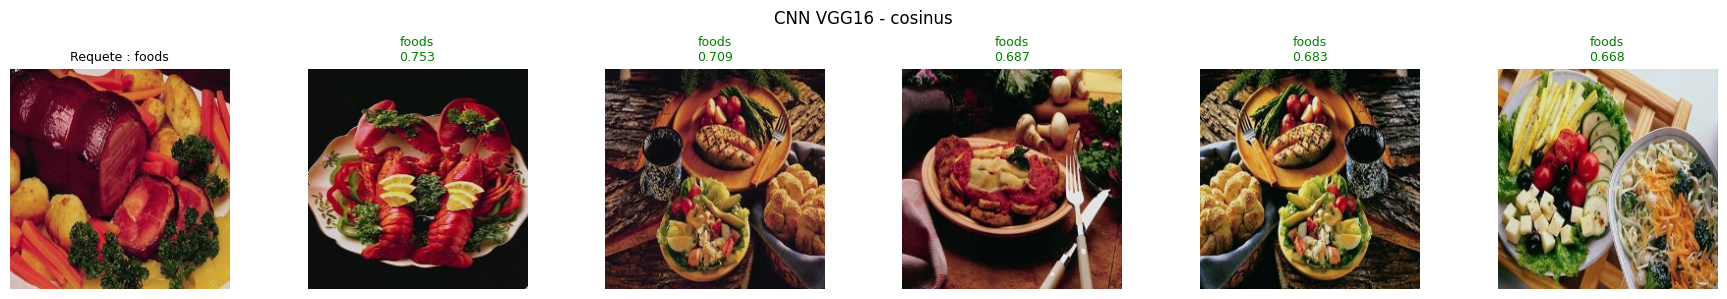

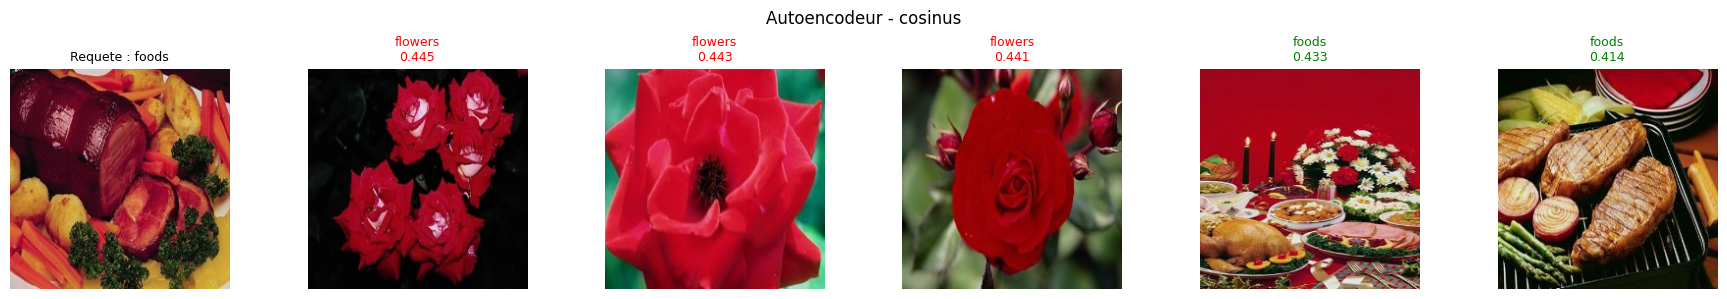

In [35]:
requetes = random.sample(range(len(X_test)), 3)
for i in requetes:
    afficher_resultats(i, cnn_test, cnn_train, "CNN VGG16 - cosinus")
    afficher_resultats(i, descriptors_test, descriptors_train, "Autoencodeur - cosinus")

### Comparaison des performances
Pour comparer les deux approches sur toutes les requêtes, on calcule la **précision@5** : pour chaque image de test, la proportion des 5 images retrouvées qui sont de la même classe que la requête. On fait ensuite la moyenne sur toutes les images de test, pour les deux descripteurs et les deux mesures.

In [36]:
def precision_moyenne(desc_test, desc_train, mesure, k=5):
    precisions = []
    for i in range(len(desc_test)):
        ordre, _ = rechercher(desc_test[i], desc_train, k, mesure)
        precisions.append(np.mean(y_train[ordre] == y_test[i]))
    return np.mean(precisions)

for nom, dte, dtr in [('CNN VGG16', cnn_test, cnn_train),
                      ('Autoencodeur', descriptors_test, descriptors_train)]:
    for mesure in ['cosinus', 'euclidienne']:
        p = precision_moyenne(dte, dtr, mesure)
        print(f"{nom:14s} - {mesure:12s} : precision@5 = {p:.2f}")

CNN VGG16      - cosinus      : precision@5 = 0.96
CNN VGG16      - euclidienne  : precision@5 = 0.92
Autoencodeur   - cosinus      : precision@5 = 0.57
Autoencodeur   - euclidienne  : precision@5 = 0.46


**Interprétation :**
Sur les trois requêtes affichées :
- **Éléphants** : le CNN retrouve 5 éléphants sur 5. L'autoencodeur en retrouve 4, avec une image de montagne verte en 4e position : elle a des couleurs proches (ciel bleu, sol vert et jaune) mais aucun éléphant.
- **Fleurs** : les deux méthodes retrouvent 5 fleurs. Cette classe est facile car toutes les images ont une fleur claire sur un fond noir, donc la couleur suffit. L'autoencodeur a même des scores plus élevés que le CNN.
- **Montagnes** : les deux méthodes retrouvent 5 images de montagnes. L'autoencodeur choisit des images avec beaucoup de bleu et de blanc, dont une avec un bateau et une avec un randonneur.

Les précisions moyennes sur les 100 requêtes confirment cela :

| Descripteur | Cosinus | Euclidienne |
|---|---|---|
| CNN VGG16 | 0.96 | 0.92 |
| Autoencodeur | 0.57 | 0.46 |

Le CNN est bien meilleur. Ses descripteurs contiennent une information sémantique apprise sur ImageNet : il reconnaît les objets même quand les couleurs changent. L'autoencodeur décrit surtout les couleurs, il marche bien pour les classes où la couleur suffit (fleurs) mais se trompe quand deux classes ont des couleurs proches.

La similarité cosinus donne de meilleurs résultats que la distance euclidienne pour les deux descripteurs (+0.04 pour le CNN, +0.11 pour l'autoencodeur), car elle compare la direction des vecteurs sans tenir compte de leur norme.

## Conclusion
Le CNN pré-entraîné VGG16, utilisé sans aucun entraînement, donne une précision de 0.96 avec la similarité cosinus. L'autoencodeur, entraîné sur nos 900 images, ne dépasse pas 0.57 : il fait du surapprentissage et son code latent garde surtout les couleurs, comme les descripteurs classiques du TP1. Le CNN profite de ce qu'il a appris sur plus d'un million d'images, ses descripteurs décrivent le contenu de l'image et réduisent le fossé sémantique.

Pour améliorer l'autoencodeur, on pourrait arrêter l'entraînement plus tôt, ajouter de l'augmentation de données ou utiliser un encodeur pré-entraîné.